# newcode1 — Optimized ESC-50 model

Two candidates were trained for 80 epochs on folds 1–3 and selected solely using fold 4. Candidate A won with **81% validation accuracy** (epoch 69); candidate B reached 80.25%. Only the selected candidate is tested below. Its saved model and training records are included in the repository.

Training used 16 kHz log-mel features, an eight-convolution network, time/frequency masking, AdamW, cosine scheduling, dropout and label smoothing. The selected model uses no mixup. See `docs/OPTIMIZATION.md` for full reproduction commands and limitations.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
MODEL = ROOT / "artifacts/optimized/audionet.ckpt"
selection = json.loads((ROOT / "artifacts/optimization_selection.json").read_text())
display(pd.DataFrame([{k:r[k] for k in ["candidate","validation_accuracy","selected_epoch"]} for r in selection["candidates"]]))
print("Selected by validation:",selection["winner"])

,candidate,validation_accuracy,selected_epoch
0,candidate-a,0.8100,69
1,candidate-b,0.8025,73


Selected by validation: candidate-a


In [2]:
from test import main as test_model
test_model(["--checkpoint", str(MODEL), "--output-dir", str(ROOT / "artifacts/optimized/test")])

Using cached features: C:\Users\ryan\Desktop\work folder\new code\data\cache\d4f85a90547025fcf486.pt


{
  "test_fold": 5,
  "samples": 400,
  "accuracy": 0.67,
  "loss": 1.2329133605957032,
  "selected_epoch": 69,
  "validation_accuracy": 0.81,
  "checkpoint": "C:\\Users\\ryan\\Desktop\\work folder\\new code\\artifacts\\optimized\\audionet.ckpt",
  "checkpoint_sha256": "2c97292a6aa16a5b1179bfa9d5fda55849f8b783274dc4de2461622cb2f46b9d",
  "environment": {
    "python": "3.12.11",
    "torch": "2.8.0+cu129",
    "torchaudio": "2.8.0+cu129",
    "numpy": "2.2.4",
    "device": "cuda",
    "gpu": "NVIDIA GeForce RTX 4060 Laptop GPU"
  },
  "chance_accuracy": 0.02,
  "macro_f1": 0.6546288826412665
}
Test results saved to C:\Users\ryan\Desktop\work folder\new code\artifacts\optimized\test


,samples,accuracy,validation_accuracy,selected_epoch,macro_f1
0,400,0.67,0.81,69,0.654629


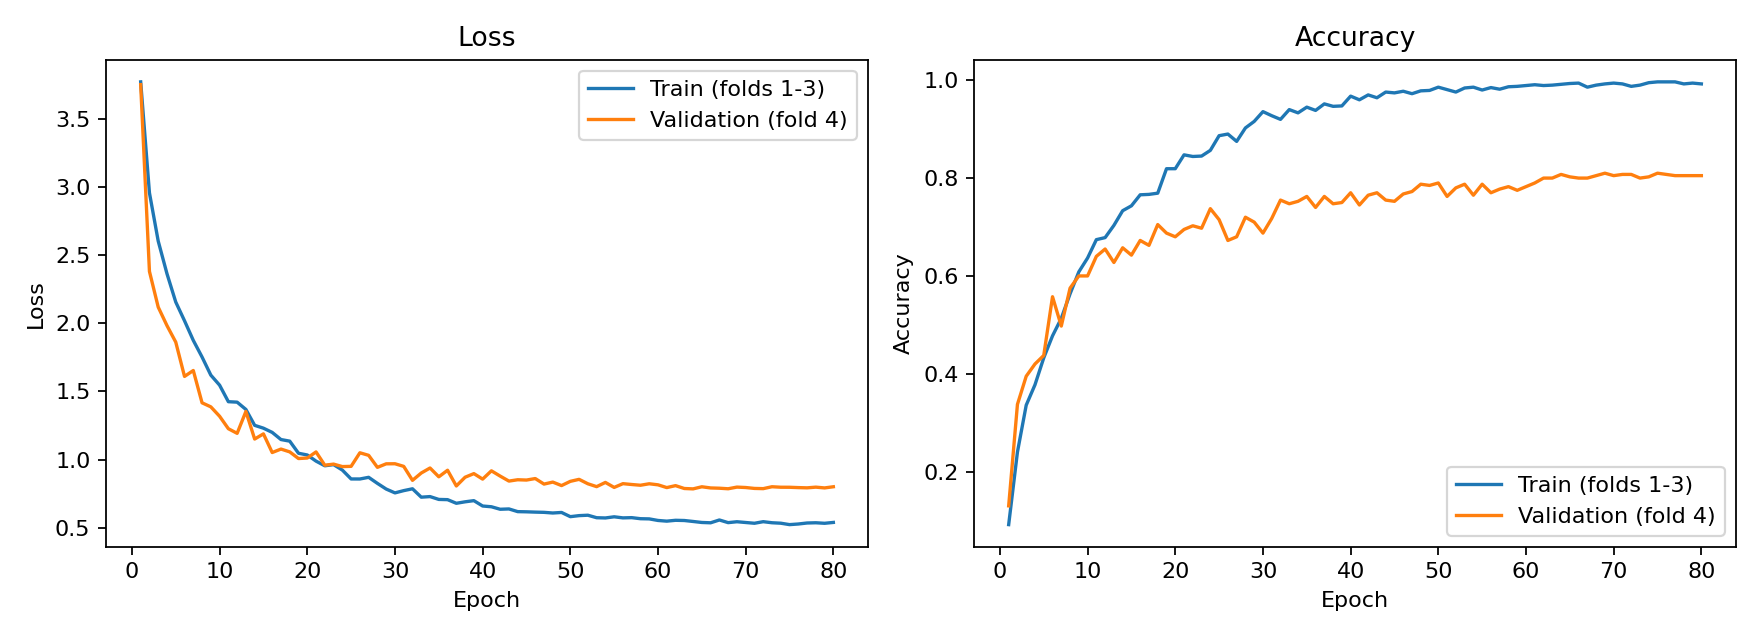

In [2]:
metrics = json.loads((ROOT / "artifacts/optimized/test/test_metrics.json").read_text())
display(pd.DataFrame([{k:metrics[k] for k in ["samples","accuracy","validation_accuracy","selected_epoch","macro_f1"]}]))
display(Image(filename=str(ROOT / "artifacts/optimized/training_curves.png")))
from visualize_results import create_visualizations
VISUALS = create_visualizations(ROOT / "artifacts/optimized", ROOT / "data/ESC-50-master")

## Most confused sound pairs
The top ten directed mistakes: the true sound is on the left of each arrow and the predicted sound on the right. Counts come from saved test predictions, excluding correct answers. Each class has only eight test clips, so small counts should be interpreted cautiously.

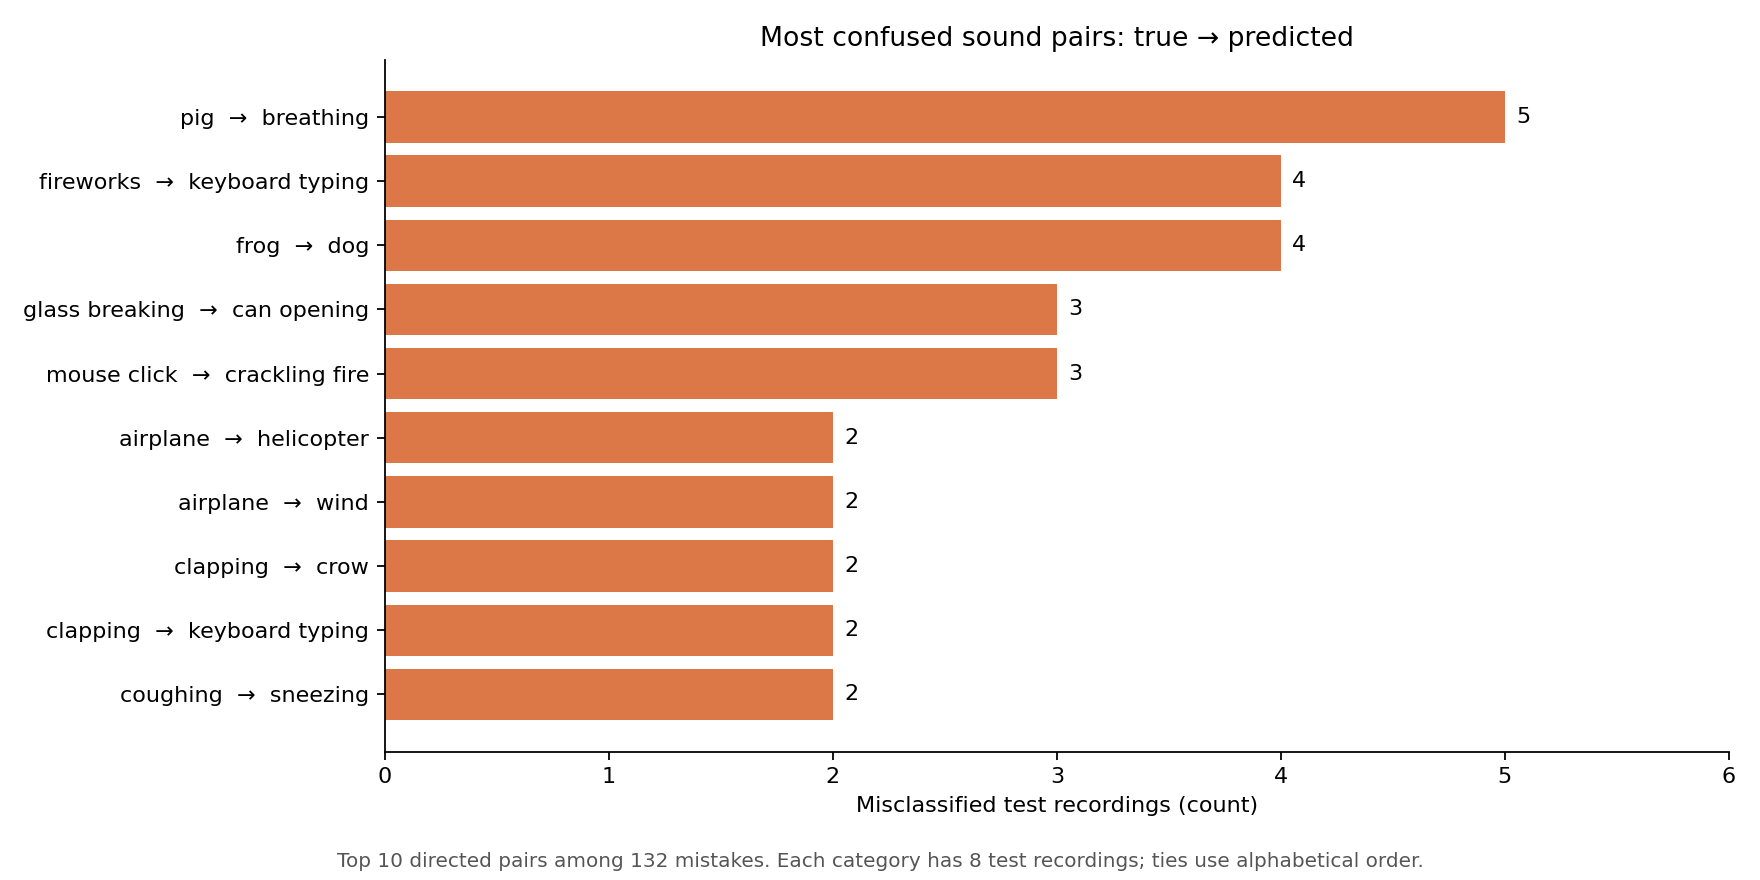

In [3]:
display(Image(filename=str(VISUALS / "most_confused_pairs.png")))

## Correct vs incorrect prediction confidence
Compare how confident the model was when right and wrong. Each group is normalized separately so its different size does not dominate the chart. Confidence is not a calibrated probability of correctness.

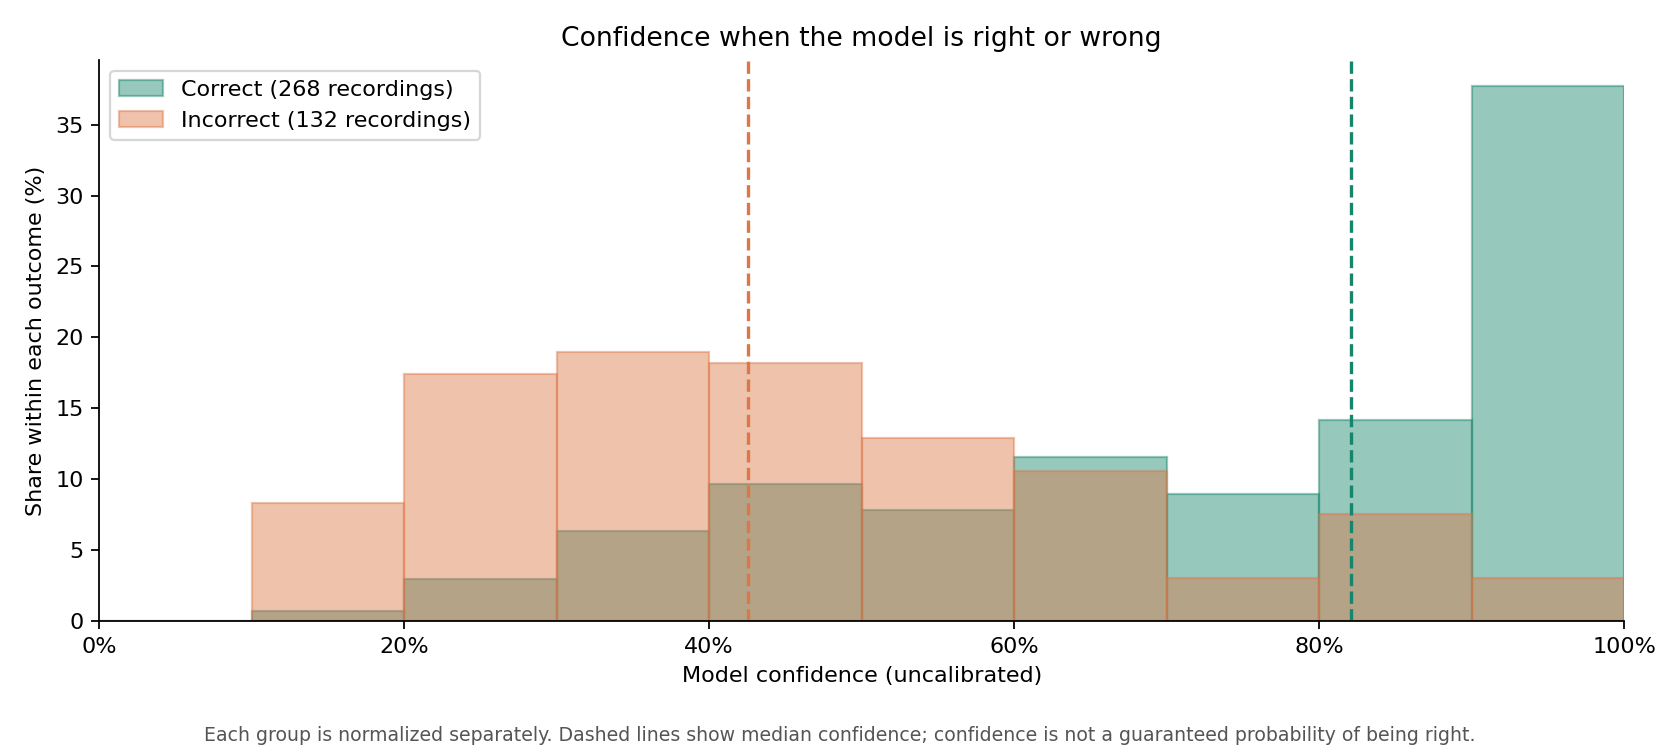

In [4]:
display(Image(filename=str(VISUALS / "confidence_correct_vs_incorrect.png")))

## Waveform and spectrogram examples
One correctly classified recording and one mistake. The waveform shows amplitude over time; the spectrogram shows the features given to the model. Examples are chosen deterministically from existing predictions, not to represent all audio. Their filenames, labels, and confidence are shown in the figure.

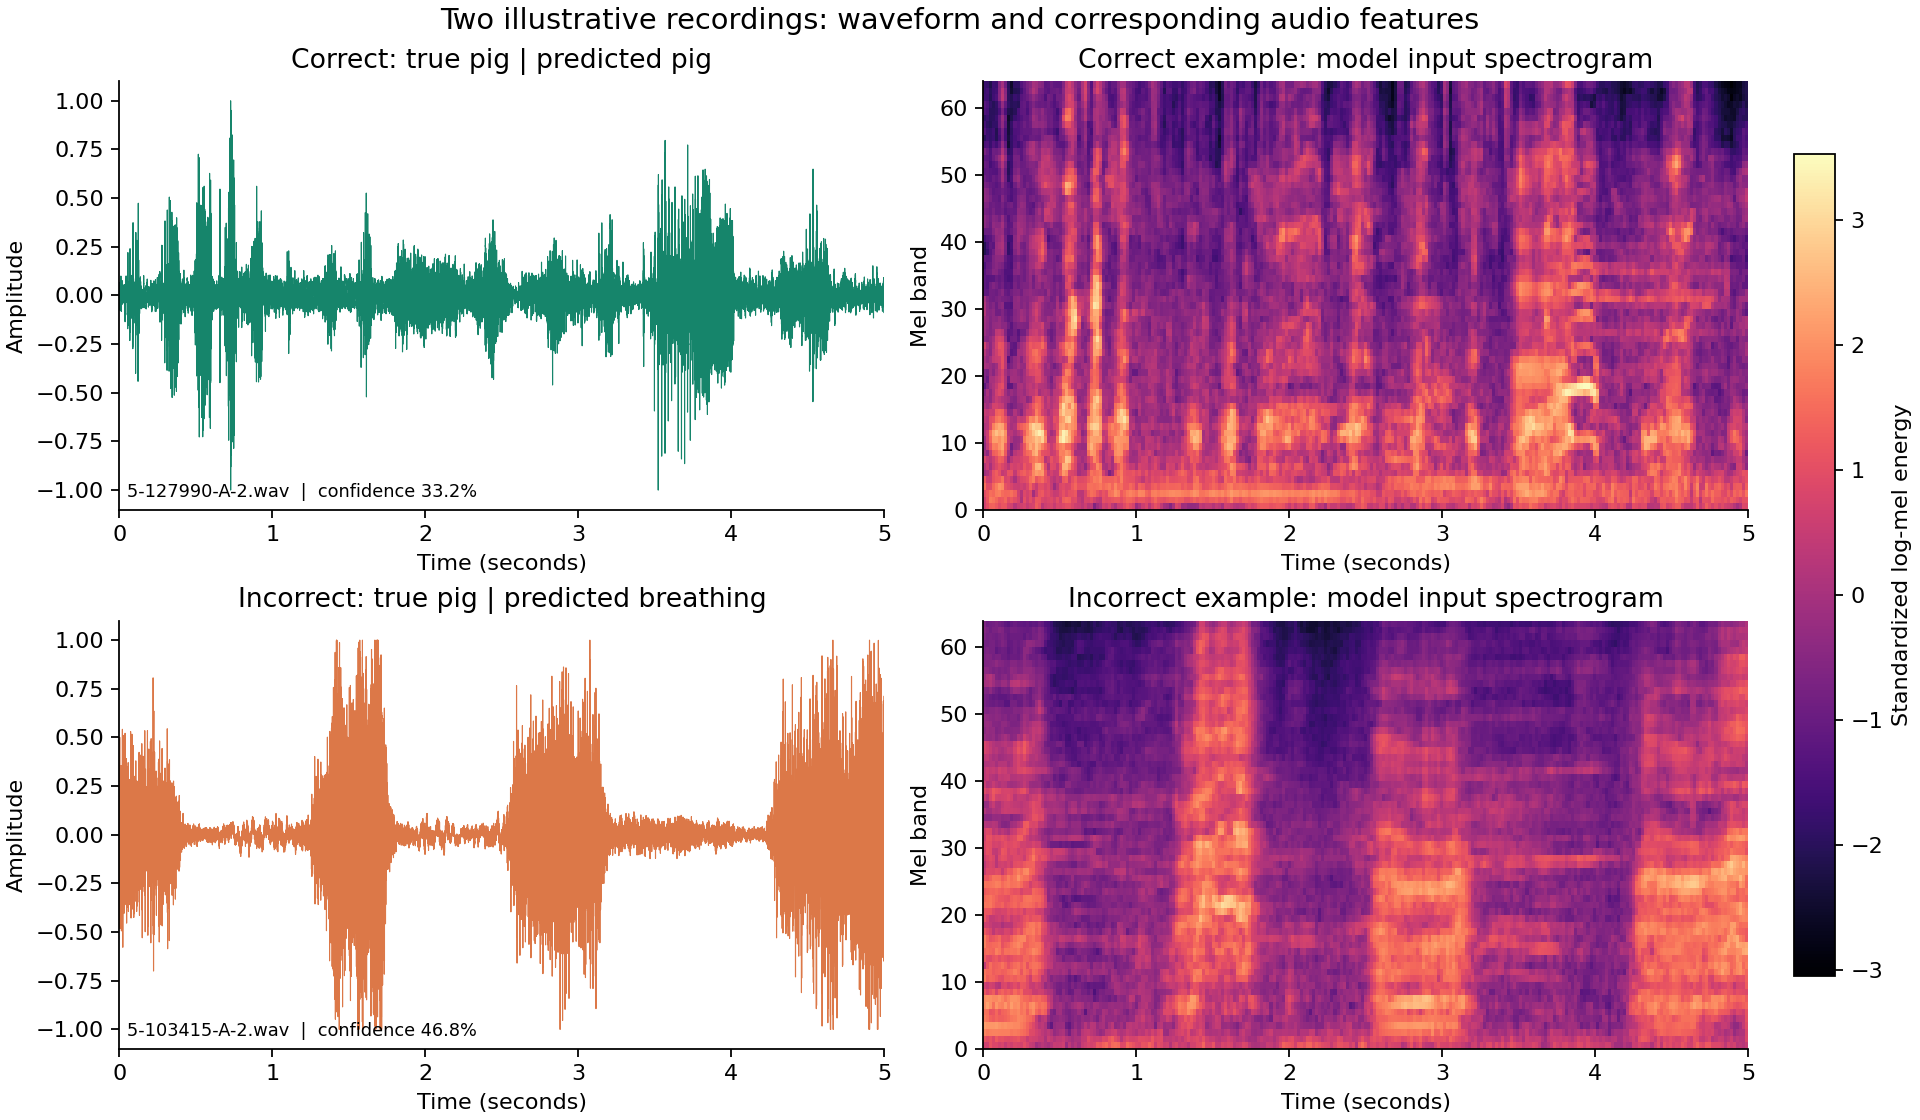

In [5]:
display(Image(filename=str(VISUALS / "waveform_spectrogram_examples.png")))

## Detailed results
Expand the complete 50-class confusion matrix when you want to inspect every category.

[Open the confusion matrix as an image](artifacts/optimized/test/confusion_matrix.png) if your viewer does not support expanding it.


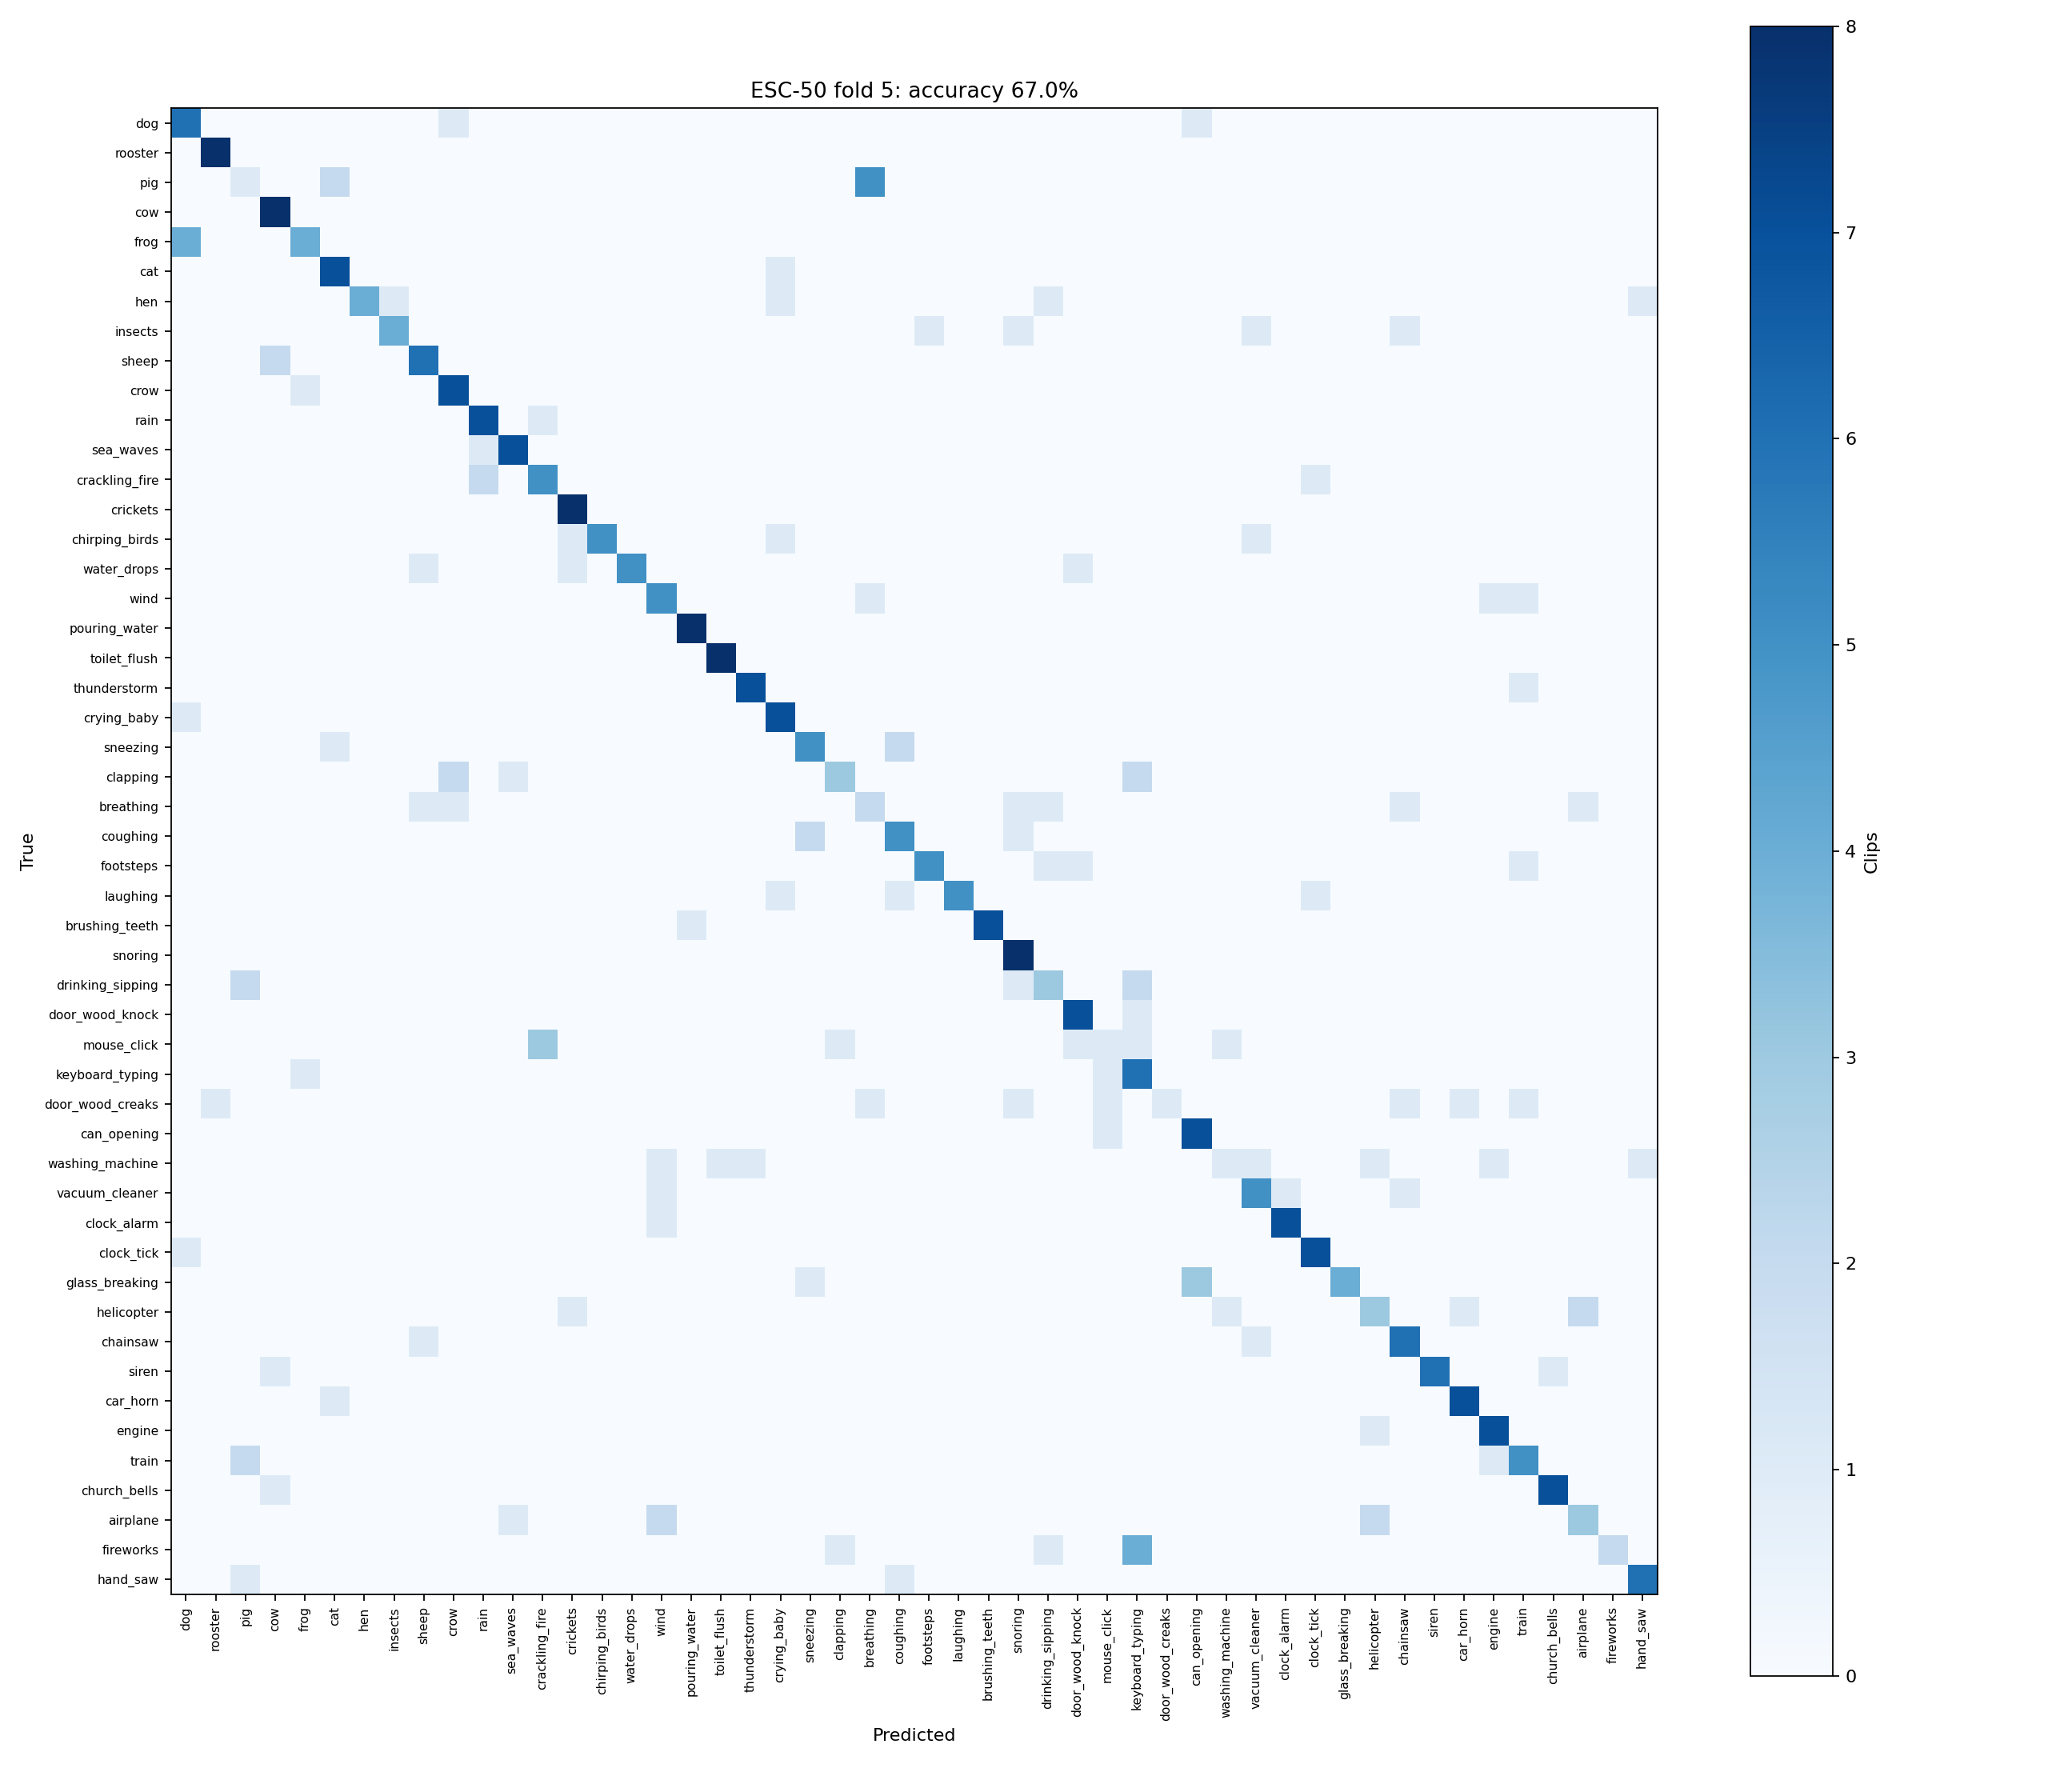

In [6]:
from visualize_results import display_confusion_matrix
display_confusion_matrix(ROOT / "artifacts/optimized/test/confusion_matrix.png")